In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from scipy import stats
from sklearn.preprocessing import StandardScaler

In [ ]:
df_path = "/content/drive/MyDrive/MBKM/Data/Data Aqi Pollutand dan Meteorologi Bundaran HI.xlsx"
df = pd.read_excel(df_path)

In [ ]:
df

,datetime,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
0,2022-01-01 00:00:00,56.0,79.0,32.8,16.2,24.6,30.2,25.91,0,23.23,0.41,83.18,3.18
1,2022-01-01 01:00:00,56.6,82.8,26.8,19.0,22.6,29.8,26.24,0,23.25,0.00,83.38,3.12
2,2022-01-01 02:00:00,56.6,76.8,36.8,17.4,28.8,18.0,28.64,0,23.42,0.00,83.97,3.10
3,2022-01-01 03:00:00,60.4,83.8,41.0,15.2,26.6,18.0,29.21,0,23.34,0.00,84.78,3.12
4,2022-01-01 04:00:00,56.8,80.2,33.0,13.2,25.2,27.0,29.92,0,23.16,0.00,85.51,3.12
...,...,...,...,...,...,...,...,...,...,...,...,...,...
26299,2024-12-31 19:00:00,30.0,41.0,12.0,22.0,11.0,20.0,25.92,0,23.43,0.00,85.09,3.06
26300,2024-12-31 20:00:00,30.0,41.0,12.0,22.0,11.0,21.0,25.47,0,23.25,0.03,85.41,3.13
26301,2024-12-31 21:00:00,31.0,43.0,12.0,22.0,11.0,21.0,25.38,0,23.25,0.16,86.31,3.29
26302,2024-12-31 22:00:00,32.0,45.0,13.0,22.0,11.0,21.0,25.52,0,23.38,0.21,87.68,3.41


In [ ]:
df.head(10)

,datetime,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
0,2022-01-01 00:00:00,56.0,79.0,32.8,16.2,24.6,30.2,25.91,0,23.23,0.41,83.18,3.18
1,2022-01-01 01:00:00,56.6,82.8,26.8,19.0,22.6,29.8,26.24,0,23.25,0.00,83.38,3.12
2,2022-01-01 02:00:00,56.6,76.8,36.8,17.4,28.8,18.0,28.64,0,23.42,0.00,83.97,3.10
3,2022-01-01 03:00:00,60.4,83.8,41.0,15.2,26.6,18.0,29.21,0,23.34,0.00,84.78,3.12
4,2022-01-01 04:00:00,56.8,80.2,33.0,13.2,25.2,27.0,29.92,0,23.16,0.00,85.51,3.12
5,2022-01-01 05:00:00,58.6,83.2,38.0,12.4,28.0,30.0,30.92,0,22.82,0.05,86.35,3.07
6,2022-01-01 06:00:00,55.8,78.0,21.6,19.6,28.6,27.8,31.22,86,22.70,0.00,86.57,2.92
7,2022-01-01 07:00:00,57.2,77.6,37.0,12.2,25.8,13.2,31.56,262,22.55,0.00,84.37,3.14
8,2022-01-01 08:00:00,59.6,84.0,31.6,13.0,28.6,22.8,30.81,371,22.71,0.00,80.24,3.36
9,2022-01-01 09:00:00,52.4,72.4,31.4,13.2,24.4,14.2,30.67,599,22.96,0.00,76.01,3.60


In [ ]:
df.dtypes

,0
datetime,datetime64[ns]
PM10,float64
PM2.5,float64
SO2,float64
CO,float64
O3,float64
NO2,float64
Suhu Udara,float64
Radiasi Matahari,int64
Suhu Titik Embun,float64


In [ ]:
df.isnull().sum()

,0
datetime,0
PM10,0
PM2.5,0
SO2,0
CO,0
O3,0
NO2,0
Suhu Udara,0
Radiasi Matahari,0
Suhu Titik Embun,0


In [ ]:
df.isnull().sum()

,0
datetime,0
PM10,10814
PM2.5,10977
SO2,10871
CO,10886
O3,10844
NO2,10826
Suhu Udara,0
Radiasi Matahari,0
Suhu Titik Embun,0


In [ ]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

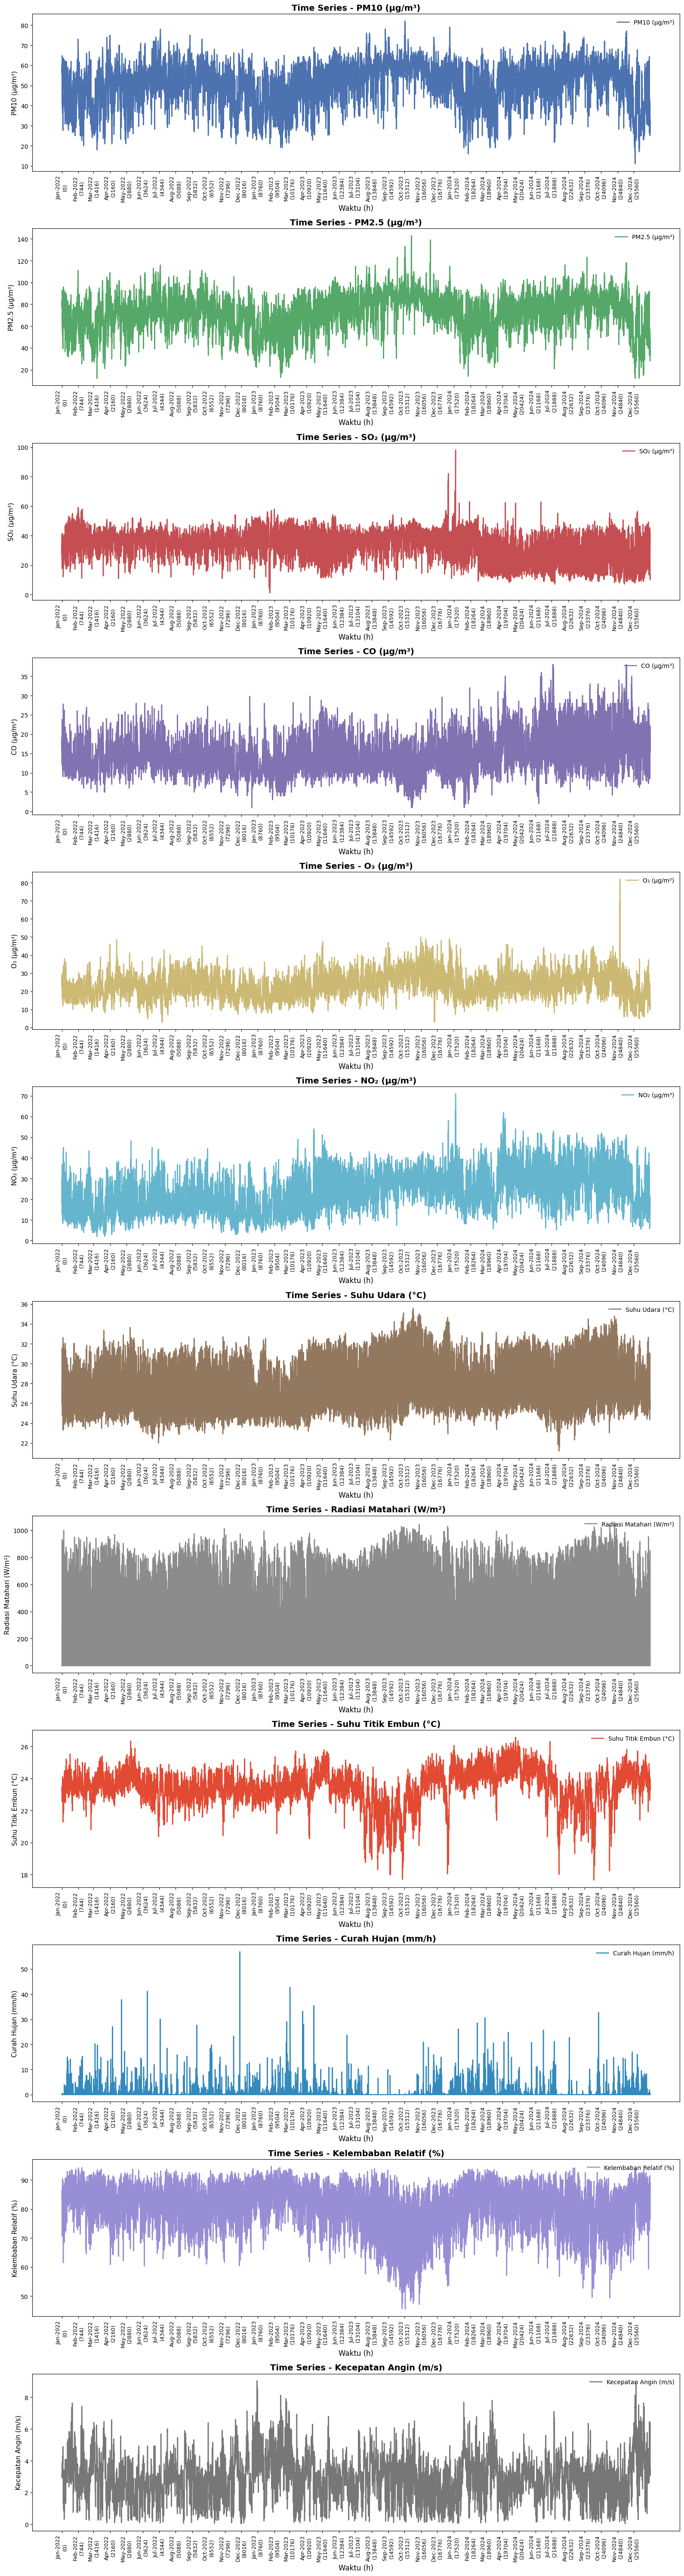

In [ ]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)
df_ts = df_ts.sort_index()

hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()




In [ ]:
df_ts.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,50.88,72.33,33.80,14.66,23.71,23.71,27.48,219.84,23.43,0.60,81.46,2.86
std,11.34,17.66,11.78,5.99,7.37,10.84,2.49,293.14,1.08,2.08,8.34,1.27
min,11.00,12.00,1.00,1.00,3.00,2.00,21.18,0.00,17.66,0.00,45.50,0.04
25%,44.00,61.40,26.80,10.40,19.00,15.00,25.41,0.00,22.92,0.00,76.45,1.96
50%,53.00,74.40,37.00,13.40,23.40,23.20,26.94,13.00,23.54,0.00,83.42,2.77
75%,59.00,85.00,42.00,18.00,28.00,31.40,29.44,445.00,24.13,0.20,88.02,3.63
max,82.00,143.00,98.00,38.00,82.00,71.00,35.58,1056.00,26.57,56.89,94.68,9.03


In [ ]:
df.replace(['-', ''], np.nan, inplace=True)

for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df_numeric = df.drop(columns=["datetime"])
datetime_col = df["datetime"]

In [ ]:
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)


In [ ]:
imputer = KNNImputer(n_neighbors=5)
df_scaled_imputed = imputer.fit_transform(df_scaled)

df_imputed = pd.DataFrame(scaler.inverse_transform(df_scaled_imputed), columns=df_numeric.columns)
df_imputed["datetime"] = datetime_col
df_imputed = df_imputed.set_index("datetime")

In [ ]:
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
datetime,,,,,,,,,,,,
2022-01-01 00:00:00,56.0,79.0,32.8,16.2,24.6,30.2,25.91,0.0,23.23,0.41,83.18,3.18
2022-01-01 01:00:00,56.6,82.8,26.8,19.0,22.6,29.8,26.24,0.0,23.25,0.00,83.38,3.12
2022-01-01 02:00:00,56.6,76.8,36.8,17.4,28.8,18.0,28.64,0.0,23.42,0.00,83.97,3.10
2022-01-01 03:00:00,60.4,83.8,41.0,15.2,26.6,18.0,29.21,0.0,23.34,0.00,84.78,3.12
2022-01-01 04:00:00,56.8,80.2,33.0,13.2,25.2,27.0,29.92,0.0,23.16,0.00,85.51,3.12
2022-01-01 05:00:00,58.6,83.2,38.0,12.4,28.0,30.0,30.92,0.0,22.82,0.05,86.35,3.07
2022-01-01 06:00:00,55.8,78.0,21.6,19.6,28.6,27.8,31.22,86.0,22.70,0.00,86.57,2.92
2022-01-01 07:00:00,57.2,77.6,37.0,12.2,25.8,13.2,31.56,262.0,22.55,0.00,84.37,3.14
2022-01-01 08:00:00,59.6,84.0,31.6,13.0,28.6,22.8,30.81,371.0,22.71,0.00,80.24,3.36


In [ ]:
df_imputed.to_csv("df_imputed.csv", index=False, float_format='%.2f')

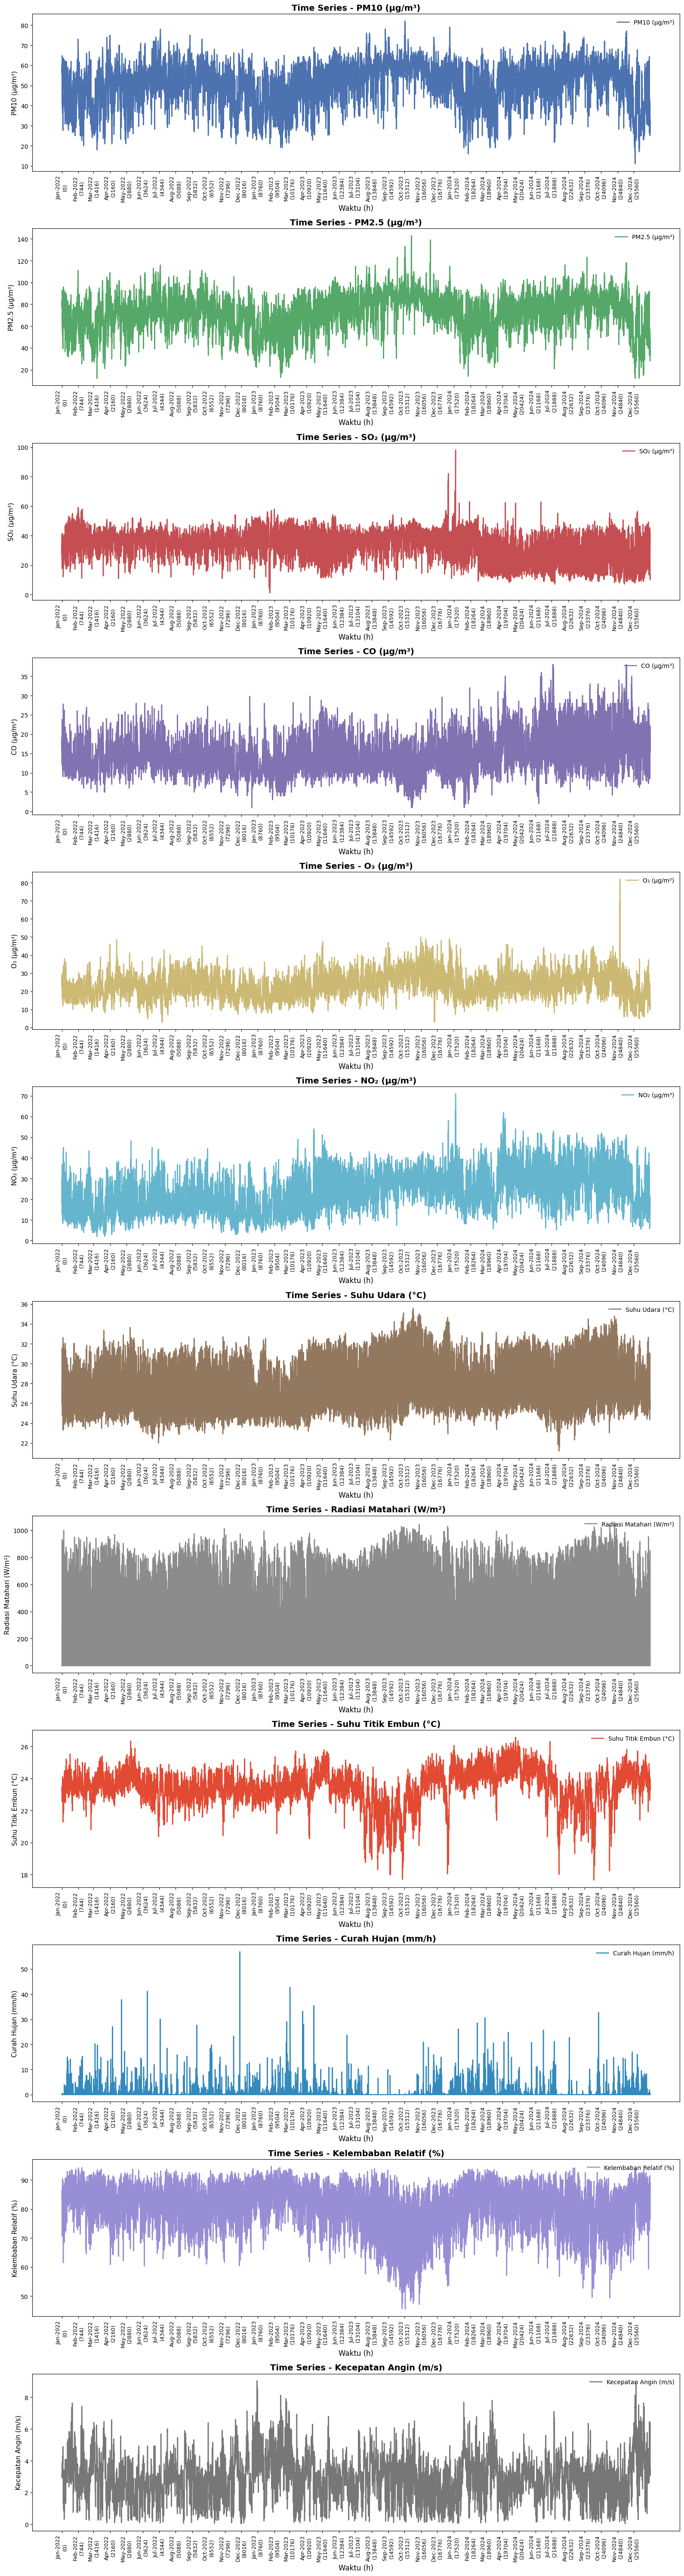

In [ ]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)
df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(), freq="MS")
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)
labels = [f"{d.strftime('%b-%Y')}\n({int(h)})" for d, h in zip(xticks, xticks_hours)]

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'Suhu Udara': 'Suhu Udara (°C)',
    'Radiasi Matahari': 'Radiasi Matahari (W/m²)',
    'Suhu Titik Embun': 'Suhu Titik Embun (°C)',
    'Curah Hujan': 'Curah Hujan (mm/h)',
    'Kelembaban Relatif': 'Kelembaban Relatif (%)',
    'Kecepatan Angin': 'Kecepatan Angin (m/s)',
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu (h)", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara,Radiasi Matahari,Suhu Titik Embun,Curah Hujan,Kelembaban Relatif,Kecepatan Angin
count,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00,26304.00
mean,50.88,72.33,33.80,14.66,23.71,23.71,27.48,219.84,23.43,0.60,81.46,2.86
std,11.34,17.66,11.78,5.99,7.37,10.84,2.49,293.14,1.08,2.08,8.34,1.27
min,11.00,12.00,1.00,1.00,3.00,2.00,21.18,0.00,17.66,0.00,45.50,0.04
25%,44.00,61.40,26.80,10.40,19.00,15.00,25.41,0.00,22.92,0.00,76.45,1.96
50%,53.00,74.40,37.00,13.40,23.40,23.20,26.94,13.00,23.54,0.00,83.42,2.77
75%,59.00,85.00,42.00,18.00,28.00,31.40,29.44,445.00,24.13,0.20,88.02,3.63
max,82.00,143.00,98.00,38.00,82.00,71.00,35.58,1056.00,26.57,56.89,94.68,9.03


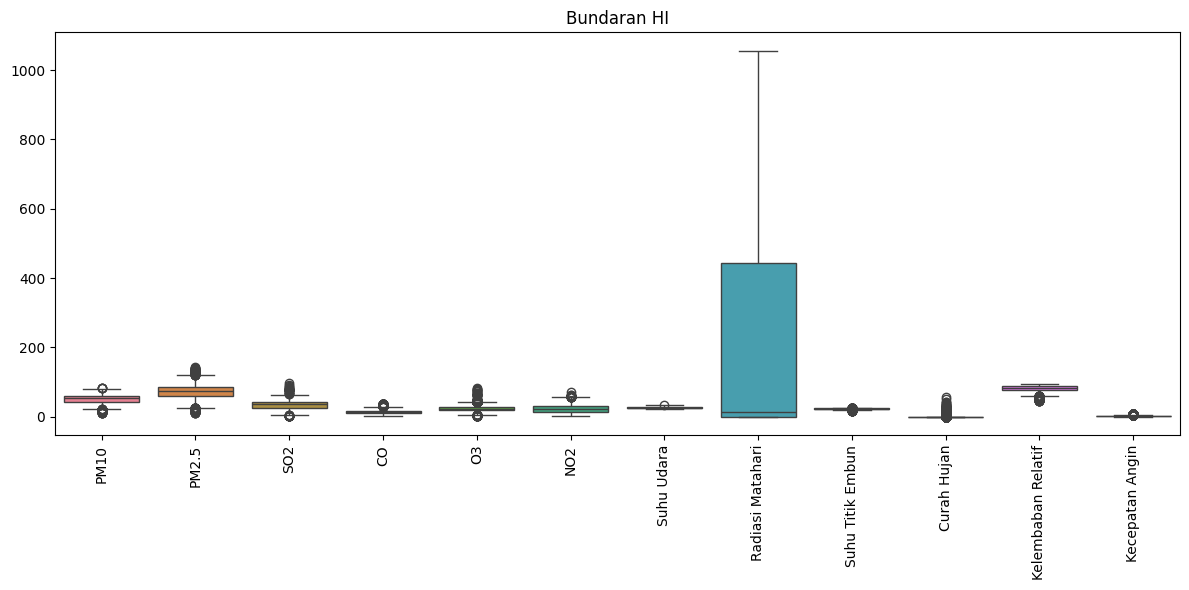

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_imputed)
plt.xticks(rotation=90)
plt.title("Bundaran HI")
plt.tight_layout()
plt.show()

